# PD — Validation

Evaluate discrimination, KS, Gini and calibration.


# PD — Validation

Validación integral de los modelos de Probability of Default (PD).

Se compararán:

- Logistic Regression — Champion interpretable
- XGBoost — Challenger

La validación considerará discriminación, distribución de riesgo, calibración y comportamiento por bandas.

### Objetivos

- Comparar AUC-ROC, Gini y KS.
- Analizar el comportamiento de los modelos por deciles de PD.
- Evaluar la concentración de defaults.
- Analizar la calibración de las probabilidades.
- Identificar diferencias entre Champion y Challenger.

In [2]:
# ============================================
# Imports
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
    brier_score_loss
)

from sklearn.calibration import calibration_curve

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [3]:
# ============================================
# Cargar dataset y preparar Train/Test
# ============================================

DATA_PATH = "../data/raw/cs-training.csv"

df = pd.read_csv(DATA_PATH)

TARGET = "SeriousDlqin2yrs"

X = df.drop(columns=[TARGET])
y = df[TARGET]

print("Dataset cargado correctamente.")
print(f"Observaciones: {len(df):,}")
print(f"Default rate: {y.mean() * 100:.2f}%")

Dataset cargado correctamente.
Observaciones: 150,000
Default rate: 6.68%


In [5]:
# ============================================
# Train / Test Split para validación
# ============================================

from sklearn.model_selection import train_test_split

X_raw = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X_raw,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Split de validación creado correctamente.")
print(f"Train: {len(X_train):,}")
print(f"Test:  {len(X_test):,}")
print(f"Default rate Train: {y_train.mean() * 100:.2f}%")
print(f"Default rate Test:  {y_test.mean() * 100:.2f}%")

Split de validación creado correctamente.
Train: 120,000
Test:  30,000
Default rate Train: 6.68%
Default rate Test:  6.68%


In [6]:
# ============================================
# Parámetros Leakage-Safe — calculados con TRAIN
# ============================================

monthly_income_median = X_train["MonthlyIncome"].median()
dependents_median = X_train["NumberOfDependents"].median()

age_invalid_train = (
    (X_train["age"] < 18) |
    (X_train["age"] > 100)
)

age_median = X_train.loc[
    ~age_invalid_train,
    "age"
].median()

debt_ratio_p99 = X_train["DebtRatio"].quantile(0.99)

utilization_p99 = (
    X_train["RevolvingUtilizationOfUnsecuredLines"]
    .quantile(0.99)
)

monthly_income_train = X_train["MonthlyIncome"].fillna(
    monthly_income_median
)

income_per_credit_line_train = (
    monthly_income_train /
    X_train["NumberOfOpenCreditLinesAndLoans"].replace(0, np.nan)
)

income_credit_median = income_per_credit_line_train.median()
income_credit_p99 = income_per_credit_line_train.quantile(0.99)

print("Parámetros Leakage-Safe calculados con TRAIN:")
print(f"MonthlyIncome median: {monthly_income_median:.2f}")
print(f"Dependents median: {dependents_median:.2f}")
print(f"Age median: {age_median:.2f}")
print(f"DebtRatio P99: {debt_ratio_p99:.2f}")
print(f"Utilization P99: {utilization_p99:.4f}")
print(f"Income/credit line median: {income_credit_median:.2f}")
print(f"Income/credit line P99: {income_credit_p99:.2f}")

Parámetros Leakage-Safe calculados con TRAIN:
MonthlyIncome median: 5390.00
Dependents median: 0.00
Age median: 52.00
DebtRatio P99: 4977.00
Utilization P99: 1.0944
Income/credit line median: 722.22
Income/credit line P99: 5390.00


In [7]:
# ============================================
# Feature Engineering — Leakage-Safe
# ============================================

def build_pd_features_safe(
    data,
    monthly_income_median,
    dependents_median,
    age_median,
    debt_ratio_p99,
    utilization_p99,
    income_credit_median,
    income_credit_p99
):
    
    df_fe = data.copy()

    # ----------------------------
    # Imputaciones
    # ----------------------------
    df_fe["MonthlyIncome_imputed"] = (
        df_fe["MonthlyIncome"]
        .fillna(monthly_income_median)
    )

    df_fe["NumberOfDependents_imputed"] = (
        df_fe["NumberOfDependents"]
        .fillna(dependents_median)
    )

    # ----------------------------
    # Edad
    # ----------------------------
    df_fe["age_invalid"] = (
        (df_fe["age"] < 18) |
        (df_fe["age"] > 100)
    ).astype(int)

    df_fe["age_clean"] = (
        df_fe["age"]
        .where(df_fe["age_invalid"] == 0, age_median)
    )

    # ----------------------------
    # Debt Ratio
    # ----------------------------
    df_fe["DebtRatio_extreme"] = (
        df_fe["DebtRatio"] > debt_ratio_p99
    ).astype(int)

    df_fe["DebtRatio_clean"] = (
        df_fe["DebtRatio"]
        .clip(upper=debt_ratio_p99)
    )

    # ----------------------------
    # Utilization
    # ----------------------------
    df_fe["Utilization_extreme"] = (
        df_fe["RevolvingUtilizationOfUnsecuredLines"]
        > utilization_p99
    ).astype(int)

    df_fe["Utilization_clean"] = (
        df_fe["RevolvingUtilizationOfUnsecuredLines"]
        .clip(upper=utilization_p99)
    )

    # ----------------------------
    # Variables de mora
    # ----------------------------
    df_fe["NumberOfTime30-59DaysPastDueNotWorse_imputed"] = (
        df_fe["NumberOfTime30-59DaysPastDueNotWorse"]
        .fillna(0)
    )

    df_fe["NumberOfTimes90DaysLate_imputed"] = (
        df_fe["NumberOfTimes90DaysLate"]
        .fillna(0)
    )

    df_fe["NumberOfTime60-89DaysPastDueNotWorse_imputed"] = (
        df_fe["NumberOfTime60-89DaysPastDueNotWorse"]
        .fillna(0)
    )

    df_fe["total_late_count"] = (
        df_fe["NumberOfTime30-59DaysPastDueNotWorse_imputed"]
        + df_fe["NumberOfTimes90DaysLate_imputed"]
        + df_fe["NumberOfTime60-89DaysPastDueNotWorse_imputed"]
    )

    df_fe["max_late_count"] = df_fe[
        [
            "NumberOfTime30-59DaysPastDueNotWorse_imputed",
            "NumberOfTimes90DaysLate_imputed",
            "NumberOfTime60-89DaysPastDueNotWorse_imputed"
        ]
    ].max(axis=1)

    df_fe["late_90plus"] = (
        df_fe["NumberOfTimes90DaysLate_imputed"] > 0
    ).astype(int)

    df_fe["any_late"] = (
        df_fe["total_late_count"] > 0
    ).astype(int)

    # ----------------------------
    # Severidad y carga de mora
    # ----------------------------
    df_fe["late_severity"] = (
        df_fe["NumberOfTime30-59DaysPastDueNotWorse_imputed"]
        + 2 * df_fe["NumberOfTime60-89DaysPastDueNotWorse_imputed"]
        + 3 * df_fe["NumberOfTimes90DaysLate_imputed"]
    )

    df_fe["late_burden"] = (
        df_fe["total_late_count"]
        * df_fe["late_severity"]
    )

    # ----------------------------
    # Capacidad de crédito
    # ----------------------------
    df_fe["income_per_credit_line"] = (
        df_fe["MonthlyIncome_imputed"]
        / df_fe["NumberOfOpenCreditLinesAndLoans"].replace(0, np.nan)
    )

    df_fe["income_per_credit_line_clean"] = (
        df_fe["income_per_credit_line"]
        .fillna(income_credit_median)
        .clip(upper=income_credit_p99)
    )

    return df_fe

In [8]:
# ============================================
# Aplicar Feature Engineering a Train y Test
# ============================================

train_fe = build_pd_features_safe(
    X_train,
    monthly_income_median,
    dependents_median,
    age_median,
    debt_ratio_p99,
    utilization_p99,
    income_credit_median,
    income_credit_p99
)

test_fe = build_pd_features_safe(
    X_test,
    monthly_income_median,
    dependents_median,
    age_median,
    debt_ratio_p99,
    utilization_p99,
    income_credit_median,
    income_credit_p99
)

safe_features = [
    "age_clean",
    "DebtRatio_clean",
    "Utilization_clean",
    "MonthlyIncome_imputed",
    "NumberOfDependents_imputed",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberRealEstateLoansOrLines",
    "total_late_count",
    "max_late_count",
    "late_90plus",
    "any_late",
    "late_severity",
    "late_burden",
    "income_per_credit_line_clean"
]

X_val_train = train_fe[safe_features].copy()
X_val_test = test_fe[safe_features].copy()

print("Feature Engineering Leakage-Safe aplicado correctamente.")
print(f"Train: {X_val_train.shape[0]:,} filas | {X_val_train.shape[1]} features")
print(f"Test:  {X_val_test.shape[0]:,} filas | {X_val_test.shape[1]} features")
print(f"NaN Train: {X_val_train.isna().sum().sum()}")
print(f"NaN Test:  {X_val_test.isna().sum().sum()}")

Feature Engineering Leakage-Safe aplicado correctamente.
Train: 120,000 filas | 14 features
Test:  30,000 filas | 14 features
NaN Train: 0
NaN Test:  0


In [9]:
# ============================================
# Logistic Regression — Champion
# ============================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_validation = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

logistic_validation.fit(
    X_val_train,
    y_train
)

print("Logistic Regression Champion entrenado correctamente.")

Logistic Regression Champion entrenado correctamente.


In [11]:
# ============================================
# Import XGBoost
# ============================================

from xgboost import XGBClassifier

print("XGBoost cargado correctamente.")

XGBoost cargado correctamente.


In [12]:
# ============================================
# XGBoost — Challenger
# ============================================

xgb_validation = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.80,
    colsample_bytree=0.80,
    min_child_weight=5,
    reg_lambda=1.0,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_validation.fit(
    X_val_train,
    y_train
)

print("XGBoost Challenger entrenado correctamente.")

XGBoost Challenger entrenado correctamente.


In [13]:
# ============================================
# Probabilidades de Default — Test
# ============================================

pd_logistic = logistic_validation.predict_proba(
    X_val_test
)[:, 1]

pd_xgb = xgb_validation.predict_proba(
    X_val_test
)[:, 1]

print("Predicciones generadas correctamente.")
print(f"Logistic Regression: {len(pd_logistic):,} PD")
print(f"XGBoost:             {len(pd_xgb):,} PD")

print(f"\nPD media Logistic: {pd_logistic.mean():.4f}")
print(f"PD media XGBoost:  {pd_xgb.mean():.4f}")
print(f"Default rate real: {y_test.mean():.4f}")

Predicciones generadas correctamente.
Logistic Regression: 30,000 PD
XGBoost:             30,000 PD

PD media Logistic: 0.0667
PD media XGBoost:  0.0671
Default rate real: 0.0668


In [14]:
# ============================================
# Métricas de validación
# ============================================

def calculate_model_metrics(y_true, y_pred_proba):
    auc_value = roc_auc_score(y_true, y_pred_proba)
    gini_value = 2 * auc_value - 1

    fpr, tpr, thresholds = roc_curve(
        y_true,
        y_pred_proba
    )

    ks_values = tpr - fpr
    ks_value = np.max(ks_values)

    ks_idx = np.argmax(ks_values)
    ks_threshold = thresholds[ks_idx]

    return auc_value, gini_value, ks_value, ks_threshold


auc_logistic_val, gini_logistic_val, ks_logistic_val, threshold_logistic_val = (
    calculate_model_metrics(y_test, pd_logistic)
)

auc_xgb_val, gini_xgb_val, ks_xgb_val, threshold_xgb_val = (
    calculate_model_metrics(y_test, pd_xgb)
)

validation_results = pd.DataFrame({
    "model": [
        "Logistic Regression - Champion",
        "XGBoost - Challenger"
    ],
    "auc_roc": [
        auc_logistic_val,
        auc_xgb_val
    ],
    "gini": [
        gini_logistic_val,
        gini_xgb_val
    ],
    "ks": [
        ks_logistic_val,
        ks_xgb_val
    ],
    "ks_threshold": [
        threshold_logistic_val,
        threshold_xgb_val
    ]
})

display(validation_results)

,model,auc_roc,gini,ks,ks_threshold
0,Logistic Regression - Champion,0.862847,0.725695,0.568547,0.058910
1,XGBoost - Challenger,0.870032,0.740064,0.583540,0.072351


In [15]:
# ============================================
# Validación por deciles de riesgo
# ============================================

validation_deciles = pd.DataFrame({
    "actual_default": y_test.values,
    "pd_logistic": pd_logistic,
    "pd_xgb": pd_xgb
})


def decile_analysis(data, pd_column):
    result = data.copy()

    # Mayor PD = mayor riesgo
    result["risk_decile"] = pd.qcut(
        result[pd_column],
        q=10,
        labels=False,
        duplicates="drop"
    )

    # 1 = mayor riesgo, 10 = menor riesgo
    result["risk_decile"] = 10 - result["risk_decile"]

    summary = (
        result
        .groupby("risk_decile", observed=False)
        .agg(
            count=("actual_default", "size"),
            avg_pd=(pd_column, "mean"),
            default_rate=("actual_default", "mean"),
            defaults=("actual_default", "sum")
        )
        .reset_index()
        .sort_values("risk_decile")
    )

    summary["avg_pd_pct"] = summary["avg_pd"] * 100
    summary["default_rate_pct"] = summary["default_rate"] * 100

    return summary


logistic_deciles = decile_analysis(
    validation_deciles,
    "pd_logistic"
)

xgb_deciles = decile_analysis(
    validation_deciles,
    "pd_xgb"
)

print("Deciles — Logistic Regression")
display(logistic_deciles)

print("Deciles — XGBoost")
display(xgb_deciles)

Deciles — Logistic Regression


,risk_decile,count,avg_pd,default_rate,defaults,avg_pd_pct,default_rate_pct
0,1,3000,0.361484,0.359667,1079,36.148366,35.966667
1,2,3000,0.103363,0.120333,361,10.336272,12.033333
2,3,3000,0.062642,0.071333,214,6.264205,7.133333
3,4,3000,0.040979,0.042333,127,4.097889,4.233333
4,5,3000,0.027356,0.027333,82,2.735584,2.733333
5,6,3000,0.020598,0.016000,48,2.059765,1.600000
6,7,3000,0.016868,0.013667,41,1.686781,1.366667
7,8,3000,0.014029,0.007667,23,1.402857,0.766667
8,9,3000,0.011458,0.007000,21,1.145768,0.700000
9,10,3000,0.008498,0.003000,9,0.849786,0.300000


Deciles — XGBoost


,risk_decile,count,avg_pd,default_rate,defaults,avg_pd_pct,default_rate_pct
0,1,3000,0.372718,0.372000,1116,37.271820,37.200000
1,2,3000,0.116913,0.118667,356,11.691317,11.866667
2,3,3000,0.065377,0.067667,203,6.537701,6.766667
3,4,3000,0.040684,0.041000,123,4.068389,4.100000
4,5,3000,0.025611,0.023000,69,2.561065,2.300000
5,6,3000,0.017163,0.016000,48,1.716253,1.600000
6,7,3000,0.012396,0.013333,40,1.239616,1.333333
7,8,3000,0.009205,0.007667,23,0.920527,0.766667
8,9,3000,0.006691,0.005000,15,0.669068,0.500000
9,10,3000,0.004273,0.004000,12,0.427313,0.400000


In [16]:
# ============================================
# Calibración de PD
# ============================================

prob_true_logistic, prob_pred_logistic = calibration_curve(
    y_test,
    pd_logistic,
    n_bins=10,
    strategy="quantile"
)

prob_true_xgb, prob_pred_xgb = calibration_curve(
    y_test,
    pd_xgb,
    n_bins=10,
    strategy="quantile"
)

brier_logistic = brier_score_loss(
    y_test,
    pd_logistic
)

brier_xgb = brier_score_loss(
    y_test,
    pd_xgb
)

print(f"Brier Score Logistic: {brier_logistic:.6f}")
print(f"Brier Score XGBoost:  {brier_xgb:.6f}")

Brier Score Logistic: 0.049421
Brier Score XGBoost:  0.048588


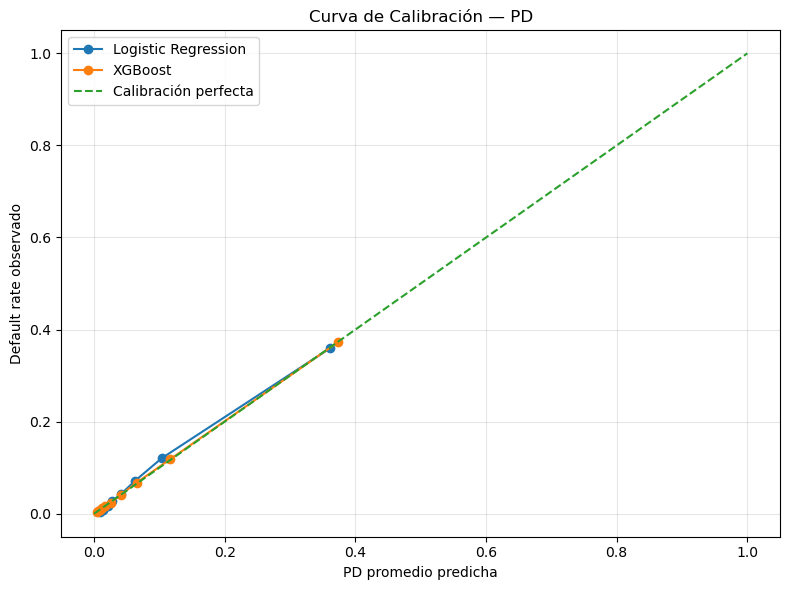

In [17]:
# ============================================
# Curva de calibración
# ============================================

plt.figure(figsize=(8, 6))

plt.plot(
    prob_pred_logistic,
    prob_true_logistic,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    prob_pred_xgb,
    prob_true_xgb,
    marker="o",
    label="XGBoost"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Calibración perfecta"
)

plt.xlabel("PD promedio predicha")
plt.ylabel("Default rate observado")
plt.title("Curva de Calibración — PD")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Cierre — Validación del modelo PD

La validación permitió comparar la **Regresión Logística** y **XGBoost** desde diferentes perspectivas.

### 1. Discriminación

| Modelo | AUC-ROC | Gini | KS |
|---|---:|---:|---:|
| Logistic Regression — Champion | 0.8628 | 0.7257 | 0.5685 |
| XGBoost — Challenger | **0.8700** | **0.7401** | **0.5835** |

XGBoost presenta una mejora moderada en las métricas de discriminación.

### 2. Ordenamiento por riesgo

Ambos modelos presentan una separación clara y monotónica de los defaults por deciles de PD.

Los clientes clasificados en los deciles de mayor riesgo presentan tasas de default considerablemente superiores a los clasificados en los deciles de menor riesgo.

En XGBoost, por ejemplo, el default observado pasa de aproximadamente **37.2% en el decil de mayor riesgo** a **0.4% en el decil de menor riesgo**.

### 3. Calibración

| Modelo | Brier Score |
|---|---:|
| Logistic Regression | 0.049421 |
| **XGBoost** | **0.048588** |

El menor Brier Score de XGBoost indica una ligera ventaja en términos de precisión probabilística.

La curva de calibración muestra que ambos modelos se mantienen relativamente próximos a la calibración perfecta.

### Conclusión

Los resultados muestran que **XGBoost supera moderadamente a la Regresión Logística en capacidad discriminativa**, manteniendo además una calibración global comparable.

La Regresión Logística conserva como ventaja principal su **interpretabilidad**, mientras que XGBoost aporta mayor capacidad para capturar relaciones no lineales.

Por ello, ambos modelos serán considerados en la etapa de **monitoreo y estabilidad** antes de tomar una decisión final sobre el modelo preferido.

### Próximo paso

Se evaluará la estabilidad de las variables y de la distribución de las PD mediante **Population Stability Index (PSI)**.